# Rossmann Store Sales. Разбор результатов

Проверяем, повышает ли история продаж точность прогноза дневной выручки.
Здесь смотрим на данные, сравниваем готовые прогнозы и разбираем ошибки.
Результаты готовит команда `python -m src.run_baseline` из корня проекта.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
config = json.loads((root / "configs/baseline.json").read_text(encoding="utf-8"))
output = root / config["output_dir"]
report = json.loads((output / "metrics.json").read_text(encoding="utf-8"))
predictions = pd.read_csv(output / "predictions.csv", parse_dates=["Date"])
scored = predictions.loc[predictions["Sales"] > 0].copy()

plt.style.use("seaborn-v0_8-whitegrid")

## Что в данных

Закрытые дни дают почти все нули. По правилам конкурса RMSPE считается только на днях с положительной выручкой.
На графиках ниже тоже используем положительные продажи. Так можно сравнить выручку по дням недели и промо без смешивания с закрытиями.

,Значение
Строки,1017209
Магазины,1115
Начало,2013-01-01
Конец,2015-07-31
Пропуски в исходных полях,0
Строки с нулевой выручкой,172871
Закрытые дни,172817
Открытые дни с нулевой выручкой,54


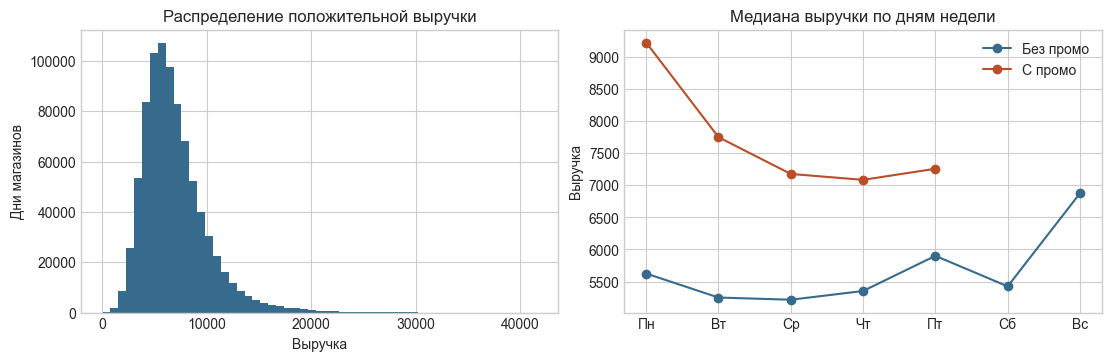

In [2]:
data = report["data"]
display(pd.Series({
    "Строки": data["rows"],
    "Магазины": data["stores"],
    "Начало": data["first_date"],
    "Конец": data["last_date"],
    "Пропуски в исходных полях": sum(data["missing"].values()),
    "Строки с нулевой выручкой": data["zero_sales"],
    "Закрытые дни": data["closed_days"],
    "Открытые дни с нулевой выручкой": data["open_zero_sales"],
}, name="Значение").to_frame())

sales = pd.read_csv(
    root / config["data_path"],
    usecols=["Sales", "DayOfWeek", "Promo"],
)
positive = sales.loc[sales["Sales"] > 0]
by_day = positive.groupby(["DayOfWeek", "Promo"])["Sales"].median().unstack()
by_day.index = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
by_day.columns = ["Без промо", "С промо"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
axes[0].hist(positive["Sales"], bins=55, color="#376b8d")
axes[0].set(title="Распределение положительной выручки", xlabel="Выручка", ylabel="Дни магазинов")
by_day.plot(ax=axes[1], marker="o", color=["#376b8d", "#ba4e28"])
axes[1].set(title="Медиана выручки по дням недели", xlabel="", ylabel="Выручка")
plt.show()

Основная масса продаж лежит заметно ниже правого края распределения. У промодней типичная выручка выше.
Этот график описывает наблюдения. Чтобы измерить пользу исторических признаков, дальше сравниваем прогнозы на одинаковых строках.

## Основной эксперимент

Обе модели используют магазин, календарь и запланированное промо. Во вторую добавлены шесть признаков истории.
Основная проверка проходит на последнем 42-дневном окне. Еще два более ранних окна показывают, повторяется ли результат.

,Строки,"RMSPE, %",MAE
Без истории,40282.0,20.33,931.78
С историей,40282.0,15.61,754.71


Относительное снижение RMSPE: 23.20%
95% бутстрап-интервал по магазинам: от 21.39% до 25.01%


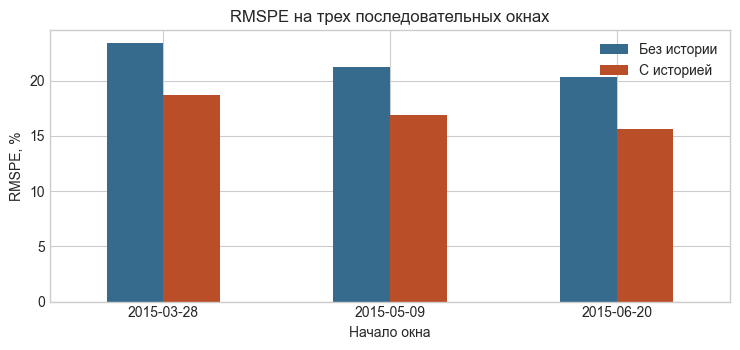

In [3]:
names = {"no_history": "Без истории", "with_history": "С историей"}
main = pd.DataFrame({names[key]: report["experiments"][key] for key in names}).T
main["rmspe"] *= 100
display(main.rename(columns={"rows": "Строки", "rmspe": "RMSPE, %", "mae": "MAE"}).round(2))

improvement = report["relative_improvement"] * 100
lower, upper = [bound * 100 for bound in report["bootstrap_95_ci"]]
print(f"Относительное снижение RMSPE: {improvement:.2f}%")
print(f"95% бутстрап-интервал по магазинам: от {lower:.2f}% до {upper:.2f}%")

windows = pd.DataFrame(report["backtest"])
scores = windows.set_index("start")[list(names)].rename(columns=names) * 100
ax = scores.plot(kind="bar", figsize=(7.5, 3.6), color=["#376b8d", "#ba4e28"], rot=0)
ax.set(title="RMSPE на трех последовательных окнах", xlabel="Начало окна", ylabel="RMSPE, %")
plt.tight_layout()
plt.show()

Ошибка с историей ниже на всех трех окнах. На последнем относительное снижение выше согласованного порога 5%.
Интервал по магазинам относится к последнему окну. Для проверки во времени смотрим на отдельные окна.

## Три исследовательских вопроса

1. Помогает ли информация о тренде?
2. Добавляют ли прошлогодние продажи полезную информацию?
3. Насколько прогноз чувствителен к разовым всплескам в истории?

Для первого вопроса убираем только тренд. Для второго убираем только выручку за дату 364 дня назад и сравниваем строки, где она есть.
Для третьего сравниваем среднее и медиану по одинаковым датам. Всплеском считаем день с выручкой хотя бы втрое выше исторической медианы для магазина и дня недели.
Срез включает магазины, у которых такие дни были, но составляли не больше 1% положительной истории до окна.

In [4]:
labels = {
    "trend": "Без тренда / с трендом",
    "last_year": "Без прошлого года / с прошлым годом",
    "spikes": "Среднее / медиана на магазинах со всплесками",
}
checks = []
for key, label in labels.items():
    first, second = report["research_checks"][key].values()
    checks.append({
        "Сравнение": label,
        "Строки": first["rows"],
        "RMSPE варианта 1, %": first["rmspe"] * 100,
        "RMSPE варианта 2, %": second["rmspe"] * 100,
    })
display(pd.DataFrame(checks).round(3))

,Сравнение,Строки,"RMSPE варианта 1, %","RMSPE варианта 2, %"
0,Без тренда / с трендом,40282,15.607,15.613
1,Без прошлого года / с прошлым годом,35252,16.229,15.588
2,Среднее / медиана на магазинах со всплесками,1363,20.078,20.344


Тренд почти не меняет RMSPE на этом окне. Прошлогодняя выручка помогает там, где известна.
В срезе из 38 магазинов со всплесками среднее оказалось немного лучше медианы по RMSPE. Этого среза мало для общего вывода о чувствительности к всплескам.

## Где модель ошибается

Разделим отложенные строки на дни с низкой выручкой, остальные промодни и остальные дни без промо.
Низкая выручка здесь означает нижние 10% положительных продаж в окне. Этот разрез нужен для анализа после прогона.

,Строки,Без истории,С историей
Срез,,,
Низкая выручка,4029,42.90,28.40
Промо,16427,15.42,13.52
Без промо,19826,16.39,13.42


,Срез,Магазин,Дата,Факт,Прогноз,"Ошибка, %"
0,Низкая выручка,852,2015-06-27,2385,3408,42.9
1,Промо,795,2015-06-30,7104,5555,-21.8
2,Без промо,913,2015-07-06,6829,8246,20.8


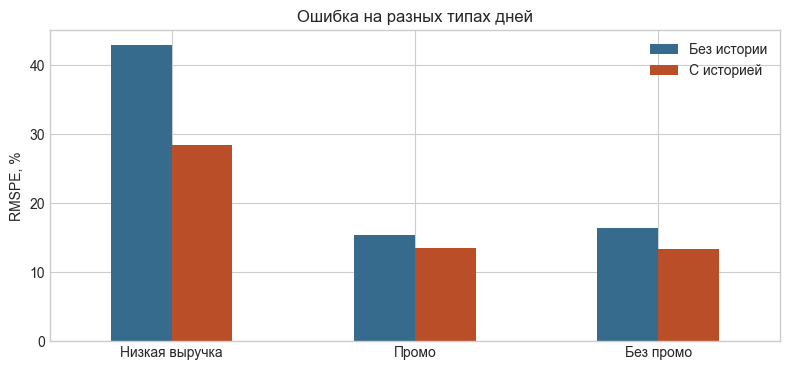

In [5]:
low = scored["Sales"] <= scored["Sales"].quantile(0.10)
groups = {
    "Низкая выручка": scored.loc[low],
    "Промо": scored.loc[~low & scored["Promo"].eq(1)],
    "Без промо": scored.loc[~low & scored["Promo"].eq(0)],
}

slices = []
examples = []
for label, rows in groups.items():
    errors = rows[list(names)].sub(rows["Sales"], axis=0).div(rows["Sales"], axis=0)
    rmspe = errors.pow(2).mean().pow(0.5).mul(100)
    slices.append({"Срез": label, "Строки": len(rows), **rmspe.rename(names).to_dict()})
    relative = errors["with_history"].abs()
    example = rows.loc[(relative - relative.quantile(0.9)).abs().idxmin()]
    examples.append({
        "Срез": label,
        "Магазин": example["Store"],
        "Дата": example["Date"].date(),
        "Факт": example["Sales"],
        "Прогноз": round(example["with_history"]),
        "Ошибка, %": round(100 * (example["with_history"] / example["Sales"] - 1), 1),
    })

by_slice = pd.DataFrame(slices).set_index("Срез")
display(by_slice.round(2))
display(pd.DataFrame(examples))
ax = by_slice[list(names.values())].plot(
    kind="bar", rot=0, figsize=(8, 3.8), color=["#376b8d", "#ba4e28"]
)
ax.set(title="Ошибка на разных типах дней", xlabel="", ylabel="RMSPE, %")
plt.tight_layout()
plt.show()

В таблице показан по одному примеру ошибки около 90-го перцентиля каждого среза.
Ниже можно посмотреть оба прогноза на одном магазине. Закрытые дни видны на графике как нули.

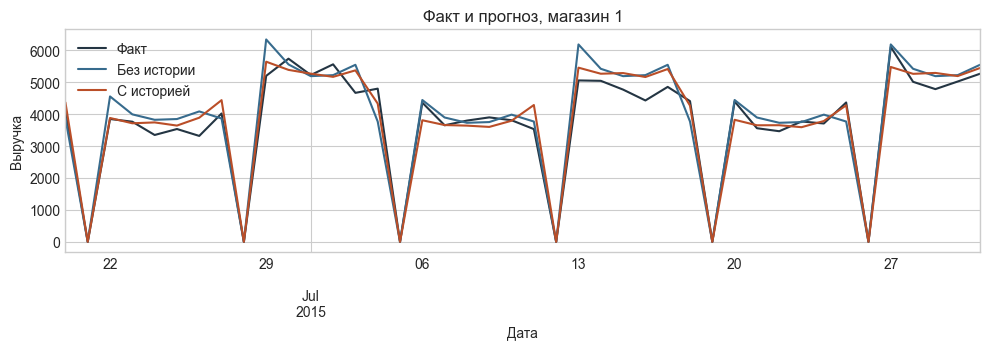

In [6]:
store_id = predictions["Store"].min()
store = predictions.loc[predictions["Store"] == store_id].sort_values("Date").set_index("Date")
lines = store[["Sales", "no_history", "with_history"]].rename(columns={"Sales": "Факт", **names})
ax = lines.plot(figsize=(10, 3.6), color=["#243543", "#376b8d", "#ba4e28"])
ax.set(title=f"Факт и прогноз, магазин {store_id}", xlabel="Дата", ylabel="Выручка")
plt.tight_layout()
plt.show()

## Вывод

Согласованный порог пройден. История продаж снижает RMSPE относительно той же линейной модели без исторических признаков.
Из дополнительных проверок самый ясный выигрыш дает прошлогодняя выручка. Срез с низкой выручкой остается трудным.
Следующая проверка может отдельно сравнить варианты для магазинов, у которых прошлогоднего наблюдения нет.